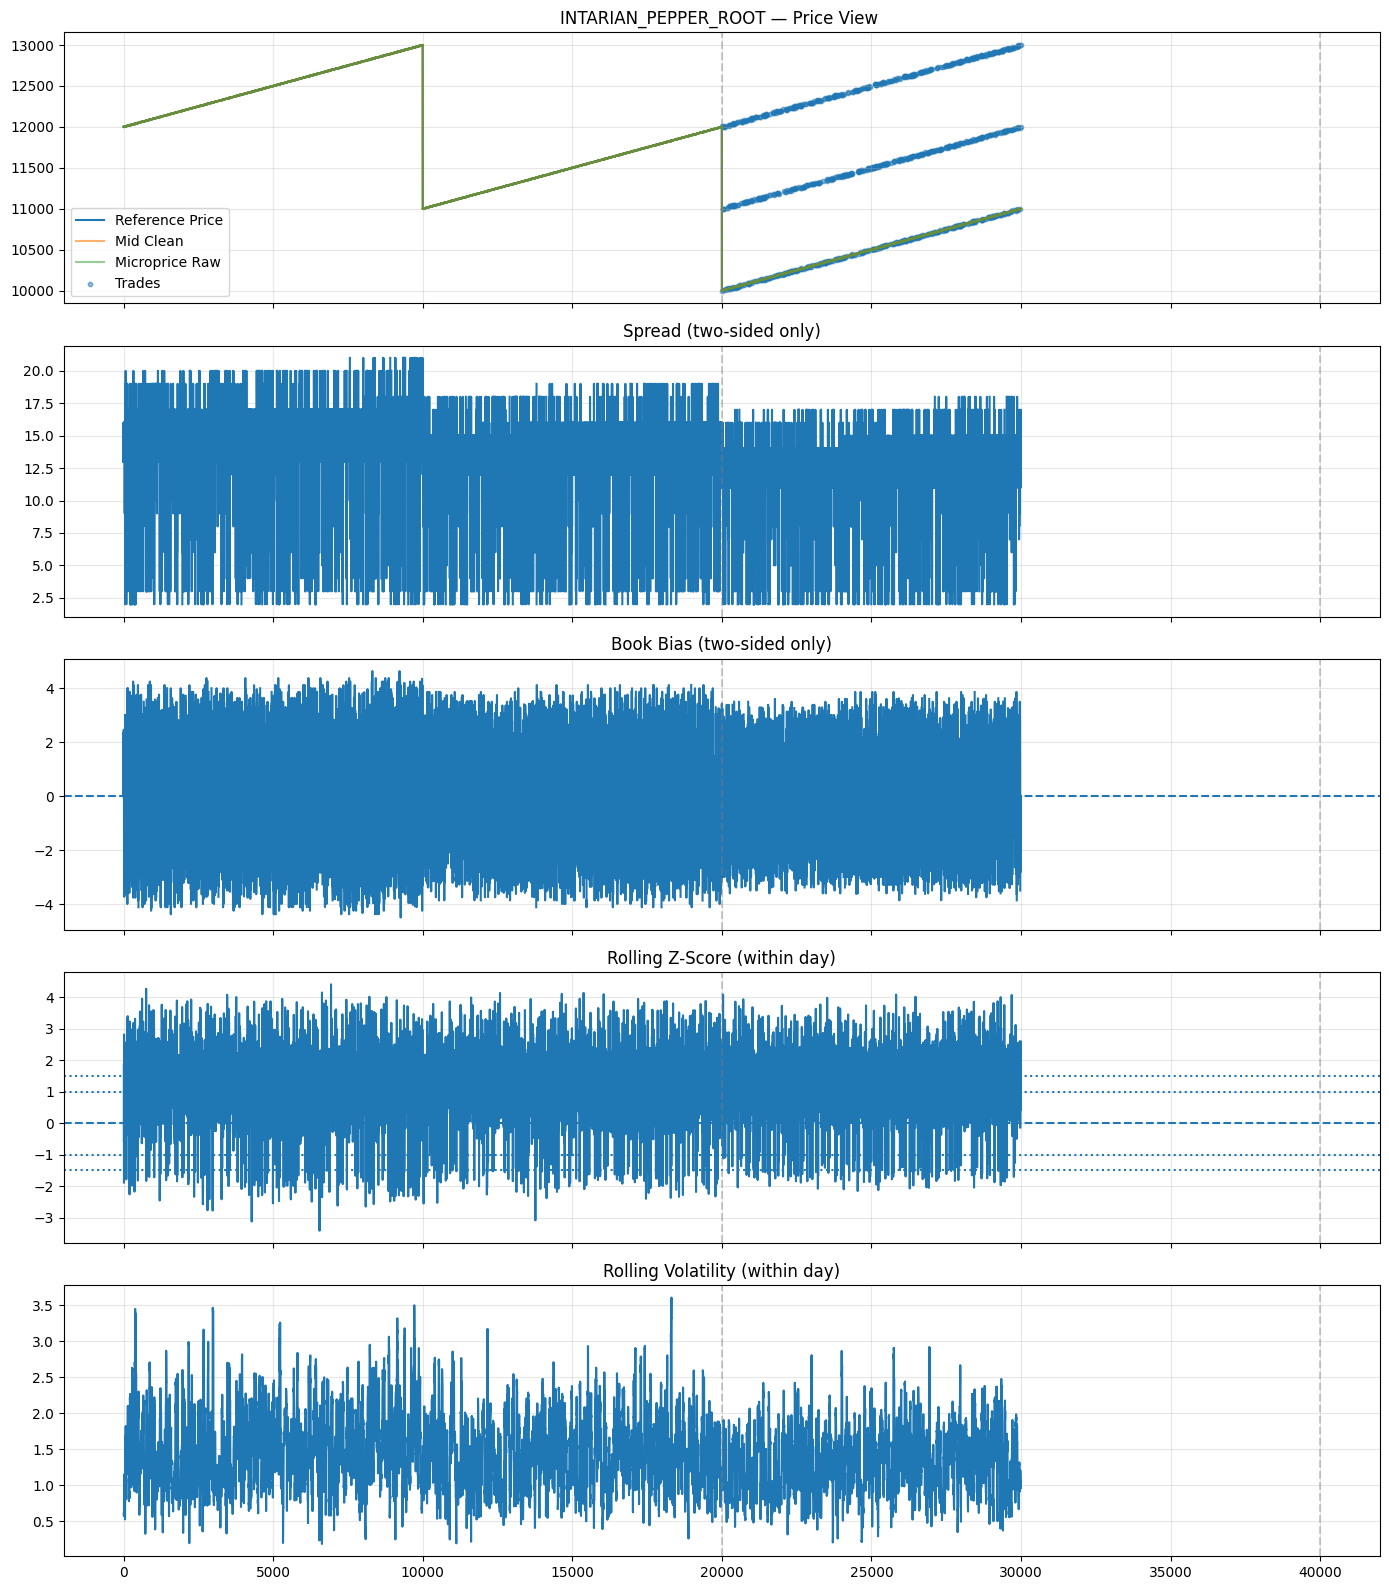

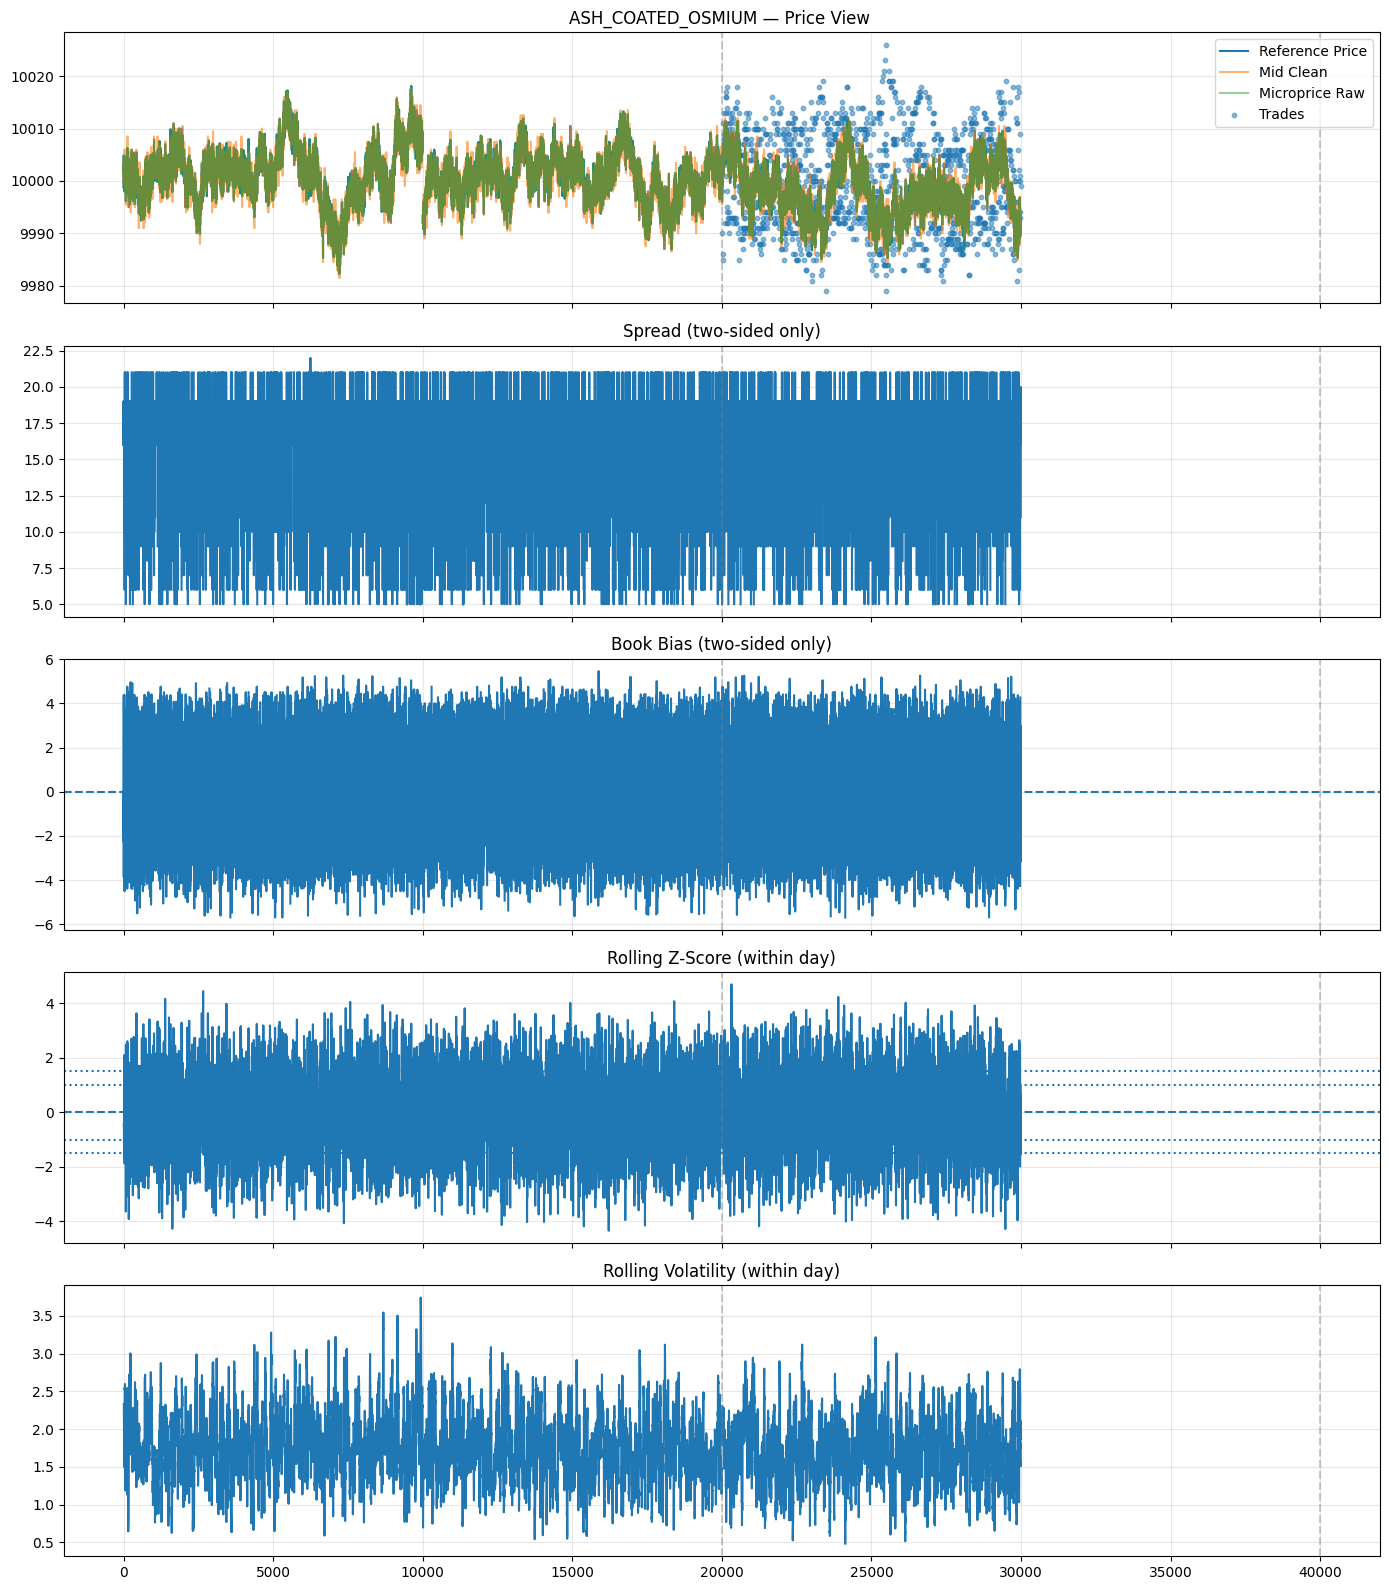

In [5]:
import io
import json
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


priceFiles = [
    "prices_round_1_day_0.csv",
    "prices_round_1_day_1.csv",
    "prices_round_1_day_2.csv",
]

tradeFiles = [
    "trades_round_1_day_0.csv",
    "trades_round_1_day_1.csv",
    "trades_round_1_day_2.csv",
]

products = ["INTARIAN_PEPPER_ROOT", "ASH_COATED_OSMIUM"]

zWindow = 40
volWindow = 25


def safeReadCsv(pathStr):
    path = Path(pathStr)
    if not path.exists():
        return None
    return pd.read_csv(path, sep=";")


def loadHistorical():
    priceFrames = []
    tradeFrames = []

    for priceFile in priceFiles:
        df = safeReadCsv(priceFile)
        if df is not None:
            priceFrames.append(df)

    for tradeFile in tradeFiles:
        df = safeReadCsv(tradeFile)
        if df is not None:
            tradeFrames.append(df)

    prices = pd.concat(priceFrames, ignore_index=True) if priceFrames else pd.DataFrame()
    trades = pd.concat(tradeFrames, ignore_index=True) if tradeFrames else pd.DataFrame()

    return prices, trades


def addDayWiseRollingStats(df):
    df = df.copy()

    df["refRet"] = np.nan
    df["rollVol"] = np.nan
    df["levelZ"] = np.nan

    for dayValue, daySlice in df.groupby("day", sort=False):
        idx = daySlice.index

        refRet = daySlice["refPrice"].diff()
        rollVol = refRet.rolling(volWindow, min_periods=10).std()

        rollMean = daySlice["refPrice"].rolling(zWindow, min_periods=10).mean()
        rollStd = daySlice["refPrice"].rolling(zWindow, min_periods=10).std()
        levelZ = (daySlice["refPrice"] - rollMean) / rollStd.replace(0, np.nan)

        df.loc[idx, "refRet"] = refRet
        df.loc[idx, "rollVol"] = rollVol
        df.loc[idx, "levelZ"] = levelZ

    return df


def enrichPrices(df):
    df = df.copy()

    df["bestBid"] = pd.to_numeric(df["bid_price_1"], errors="coerce")
    df["bestAsk"] = pd.to_numeric(df["ask_price_1"], errors="coerce")
    df["bidVol"] = pd.to_numeric(df["bid_volume_1"], errors="coerce").fillna(0.0)
    df["askVol"] = pd.to_numeric(df["ask_volume_1"], errors="coerce").abs().fillna(0.0)
    df["midInput"] = pd.to_numeric(df["mid_price"], errors="coerce")

    df["bidPresent"] = df["bestBid"].notna() & (df["bestBid"] > 0)
    df["askPresent"] = df["bestAsk"].notna() & (df["bestAsk"] > 0)
    df["twoSided"] = df["bidPresent"] & df["askPresent"]

    df["midRaw"] = np.where(
        df["twoSided"],
        (df["bestBid"] + df["bestAsk"]) / 2.0,
        np.nan,
    )

    # Carry forward last valid mid within each day
    df["midClean"] = df.groupby("day", sort=False)["midRaw"].ffill()

    df["spread"] = np.where(
        df["twoSided"],
        df["bestAsk"] - df["bestBid"],
        np.nan,
    )

    denom = df["bidVol"] + df["askVol"]
    df["micropriceRaw"] = np.where(
        df["twoSided"] & (denom > 0),
        (df["bestBid"] * df["askVol"] + df["bestAsk"] * df["bidVol"]) / denom,
        np.nan,
    )

    # Forward fill only within each day
    df["micropriceClean"] = df.groupby("day", sort=False)["micropriceRaw"].ffill()

    # Reference price:
    # prefer raw microprice when valid, else cleaned mid
    df["refPrice"] = df["micropriceRaw"]
    missingRef = df["refPrice"].isna()
    df.loc[missingRef, "refPrice"] = df.loc[missingRef, "midClean"]

    df.loc[df["refPrice"] <= 0, "refPrice"] = np.nan
    df["refPrice"] = df.groupby("day", sort=False)["refPrice"].ffill()

    df["bookBias"] = np.where(
        df["micropriceRaw"].notna() & df["midRaw"].notna(),
        df["micropriceRaw"] - df["midRaw"],
        np.nan,
    )

    df = addDayWiseRollingStats(df)

    return df


def loadRunZip(zipPathStr):
    zipPath = Path(zipPathStr)
    if not zipPath.exists():
        return None, None, None

    with zipfile.ZipFile(zipPath, "r") as zf:
        jsonName = [name for name in zf.namelist() if name.endswith(".json")][0]
        runData = json.loads(zf.read(jsonName))

    pnlDf = pd.read_csv(io.StringIO(runData["graphLog"]), sep=";")
    activityDf = pd.read_csv(io.StringIO(runData["activitiesLog"]), sep=";")

    return runData, pnlDf, activityDf


def addDaySeparators(ax, df):
    dayStarts = df.groupby("day", sort=False).head(1).index.tolist()
    for idx in dayStarts[1:]:
        ax.axvline(idx, color="gray", linestyle="--", alpha=0.4)


def plotProductDashboard(productDf, tradesDf, product, runPnlDf=None, runActivityDf=None, titleSuffix=""):
    fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)

    x = np.arange(len(productDf))

    axes[0].plot(x, productDf["refPrice"], label="Reference Price")
    axes[0].plot(x, productDf["midClean"], label="Mid Clean", alpha=0.6)
    axes[0].plot(x, productDf["micropriceRaw"], label="Microprice Raw", alpha=0.5)
    axes[0].set_title(f"{product} — Price View {titleSuffix}")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(x, productDf["spread"], label="Spread")
    axes[1].set_title("Spread (two-sided only)")
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(x, productDf["bookBias"], label="Microprice - Mid")
    axes[2].axhline(0, linestyle="--")
    axes[2].set_title("Book Bias (two-sided only)")
    axes[2].grid(True, alpha=0.3)

    axes[3].plot(x, productDf["levelZ"], label="Level Z")
    axes[3].axhline(0, linestyle="--")
    axes[3].axhline(1.0, linestyle=":")
    axes[3].axhline(-1.0, linestyle=":")
    axes[3].axhline(1.5, linestyle=":")
    axes[3].axhline(-1.5, linestyle=":")
    axes[3].set_title("Rolling Z-Score (within day)")
    axes[3].grid(True, alpha=0.3)

    axes[4].plot(x, productDf["rollVol"], label="Rolling Vol")
    axes[4].set_title("Rolling Volatility (within day)")
    axes[4].grid(True, alpha=0.3)

    for ax in axes:
        addDaySeparators(ax, productDf)

    if tradesDf is not None and not tradesDf.empty:
        if "symbol" in tradesDf.columns:
            prodTrades = tradesDf[tradesDf["symbol"] == product].copy()
        else:
            prodTrades = tradesDf[tradesDf["product"] == product].copy()

        if not prodTrades.empty and "price" in prodTrades.columns and "timestamp" in prodTrades.columns:
            prodTrades["price"] = pd.to_numeric(prodTrades["price"], errors="coerce")
            prodTrades = prodTrades[prodTrades["price"] > 0].copy()

            tsToIdx = {ts: i for i, ts in enumerate(productDf["timestamp"].tolist())}
            prodTrades = prodTrades[prodTrades["timestamp"].isin(tsToIdx.keys())].copy()

            tradeIdx = [tsToIdx[t] for t in prodTrades["timestamp"]]
            tradePx = prodTrades["price"].tolist()

            axes[0].scatter(tradeIdx, tradePx, s=10, alpha=0.5, label="Trades")
            axes[0].legend()

    plt.tight_layout()
    plt.show()

    if runPnlDf is not None and not runPnlDf.empty:
        plt.figure(figsize=(14, 4))
        plt.plot(runPnlDf["timestamp"], runPnlDf["value"])
        plt.title(f"Run PnL Curve {titleSuffix}")
        plt.grid(True, alpha=0.3)
        plt.show()

    if runActivityDf is not None and not runActivityDf.empty:
        prodRun = runActivityDf[runActivityDf["product"] == product].copy()
        if not prodRun.empty:
            prodRun["bid_price_1"] = pd.to_numeric(prodRun["bid_price_1"], errors="coerce")
            prodRun["ask_price_1"] = pd.to_numeric(prodRun["ask_price_1"], errors="coerce")
            prodRun["mid_price"] = pd.to_numeric(prodRun["mid_price"], errors="coerce")

            prodRun["twoSided"] = (
                prodRun["bid_price_1"].notna()
                & prodRun["ask_price_1"].notna()
                & (prodRun["bid_price_1"] > 0)
                & (prodRun["ask_price_1"] > 0)
            )

            prodRun["spread"] = np.where(
                prodRun["twoSided"],
                prodRun["ask_price_1"] - prodRun["bid_price_1"],
                np.nan,
            )

            plt.figure(figsize=(14, 4))
            plt.plot(prodRun["timestamp"], prodRun["mid_price"], label="Mid")
            plt.plot(prodRun["timestamp"], prodRun["spread"], label="Spread")
            plt.title(f"Run Activity Snapshot {titleSuffix}")
            plt.legend()
            plt.grid(True, alpha=0.3)
            plt.show()


def buildDashboards(runZipPath=None):
    prices, trades = loadHistorical()

    if prices.empty:
        print("No historical price files found.")
        return

    runData = None
    runPnlDf = None
    runActivityDf = None

    if runZipPath:
        runData, runPnlDf, runActivityDf = loadRunZip(runZipPath)
        if runData is not None:
            print(f"Run profit: {runData['profit']}")
            print(f"Run status: {runData['status']}")

    for product in products:
        prod = prices[prices["product"] == product].copy()
        prod = enrichPrices(prod)

        plotProductDashboard(
            productDf=prod,
            tradesDf=trades,
            product=product,
            runPnlDf=runPnlDf,
            runActivityDf=runActivityDf,
            titleSuffix=f"(run={Path(runZipPath).name})" if runZipPath else "",
        )


if __name__ == "__main__":
    # Example:
    # buildDashboards("137022.zip")
    buildDashboards()